# Approximate vehicle rectangles in an aerial parking-lot image

This notebook uses grayscale conversion, Gaussian noise reduction, Canny edges, morphological closing, the probabilistic Hough transform, and geometric grouping of compatible line segments. The result is an approximate outline: vehicle corners are rounded and some sides are hidden by glare or shadow.

## Photograph credit and license

**Photographer:** Heath Alseike<br>
**Work:** [*Above the Parking Lot (24993869647).jpg*](https://commons.wikimedia.org/wiki/File:Above_the_Parking_Lot_(24993869647).jpg), 20 January 2018<br>
**License:** [CC BY 2.0](https://creativecommons.org/licenses/by/2.0/)<br>
**Changes:** cropped, resized, converted to grayscale, filtered, and annotated.

The downloaded original is 4032 × 3024 pixels. The reproducible crop is `(x_min, y_min, x_max, y_max) = (480, 690, 2640, 1700)` in that original, followed by a 0.5 scale reduction. It was chosen because it contains separated vehicles and a broad area of open pavement.

In [1]:
from pathlib import Path
from urllib.request import Request, urlopen
import hashlib

import cv2
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

SOURCE_URL = (
    "https://commons.wikimedia.org/wiki/Special:Redirect/file/"
    "Above_the_Parking_Lot_%2824993869647%29.jpg"
)
SOURCE_PATH = DATA_DIR / "parking_lot_original.jpg"
SOURCE_SHA256 = "5f0ed971937484fb0bc91d5706bf44ec9a94d48eb16991178daac787f0ffb99c"

if not SOURCE_PATH.exists():
    request = Request(SOURCE_URL, headers={"User-Agent": "vehicle-rectangle-notebook/1.0"})
    with urlopen(request) as response:
        SOURCE_PATH.write_bytes(response.read())

digest = hashlib.sha256(SOURCE_PATH.read_bytes()).hexdigest()
assert digest == SOURCE_SHA256, f"Unexpected source file hash: {digest}"

original_bgr = cv2.imread(str(SOURCE_PATH), cv2.IMREAD_COLOR)
if original_bgr is None:
    raise RuntimeError(f"OpenCV could not read {SOURCE_PATH}")
print(f"Source: {original_bgr.shape[1]} x {original_bgr.shape[0]} px; SHA-256 {digest}")

Source: 4032 x 3024 px; SHA-256 5f0ed971937484fb0bc91d5706bf44ec9a94d48eb16991178daac787f0ffb99c


## Reproducible crop

OpenCV/NumPy indexing is `image[y_min:y_max, x_min:x_max]`. The coordinates below are recorded in the full-resolution source coordinate system.

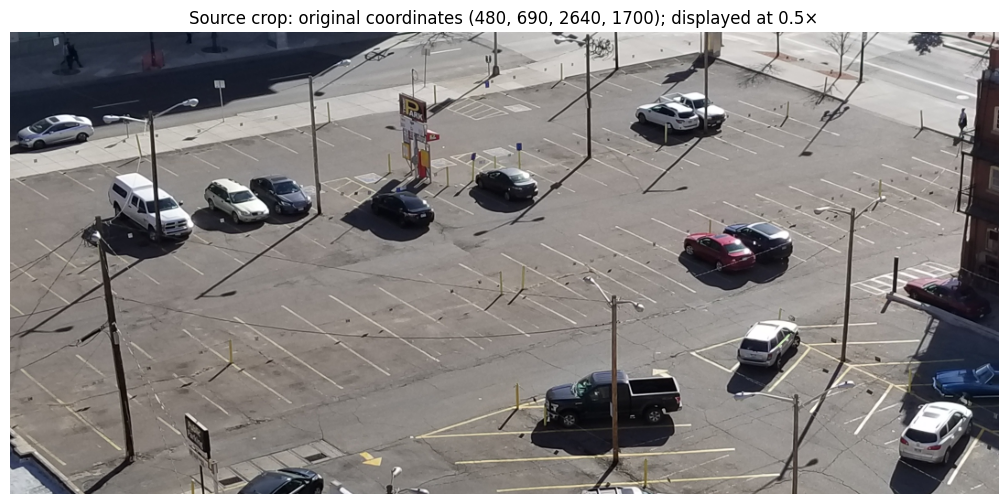

Saved /home/sadia/GNR_607/GNR-607-hough-object-extraction/results/source_crop.png (505, 1080, 3)


In [2]:
CROP_XYXY = (480, 690, 2640, 1700)
DISPLAY_SCALE = 0.5

x_min, y_min, x_max, y_max = CROP_XYXY
crop_full = original_bgr[y_min:y_max, x_min:x_max]
crop_bgr = cv2.resize(
    crop_full, None, fx=DISPLAY_SCALE, fy=DISPLAY_SCALE, interpolation=cv2.INTER_AREA
)
crop_rgb = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB)
cv2.imwrite(str(RESULTS_DIR / "source_crop.png"), crop_bgr)

plt.figure(figsize=(14, 6))
plt.imshow(crop_rgb)
plt.title(f"Source crop: original coordinates {CROP_XYXY}; displayed at {DISPLAY_SCALE:g}×")
plt.axis("off")
plt.show()
print("Saved", RESULTS_DIR / "source_crop.png", crop_bgr.shape)

## Grayscale, noise reduction, Canny edges, and closing

A 5 × 5 Gaussian filter reduces small pavement texture before Canny. Closing uses a small rectangular structuring element to bridge short breaks in the vehicle edges.

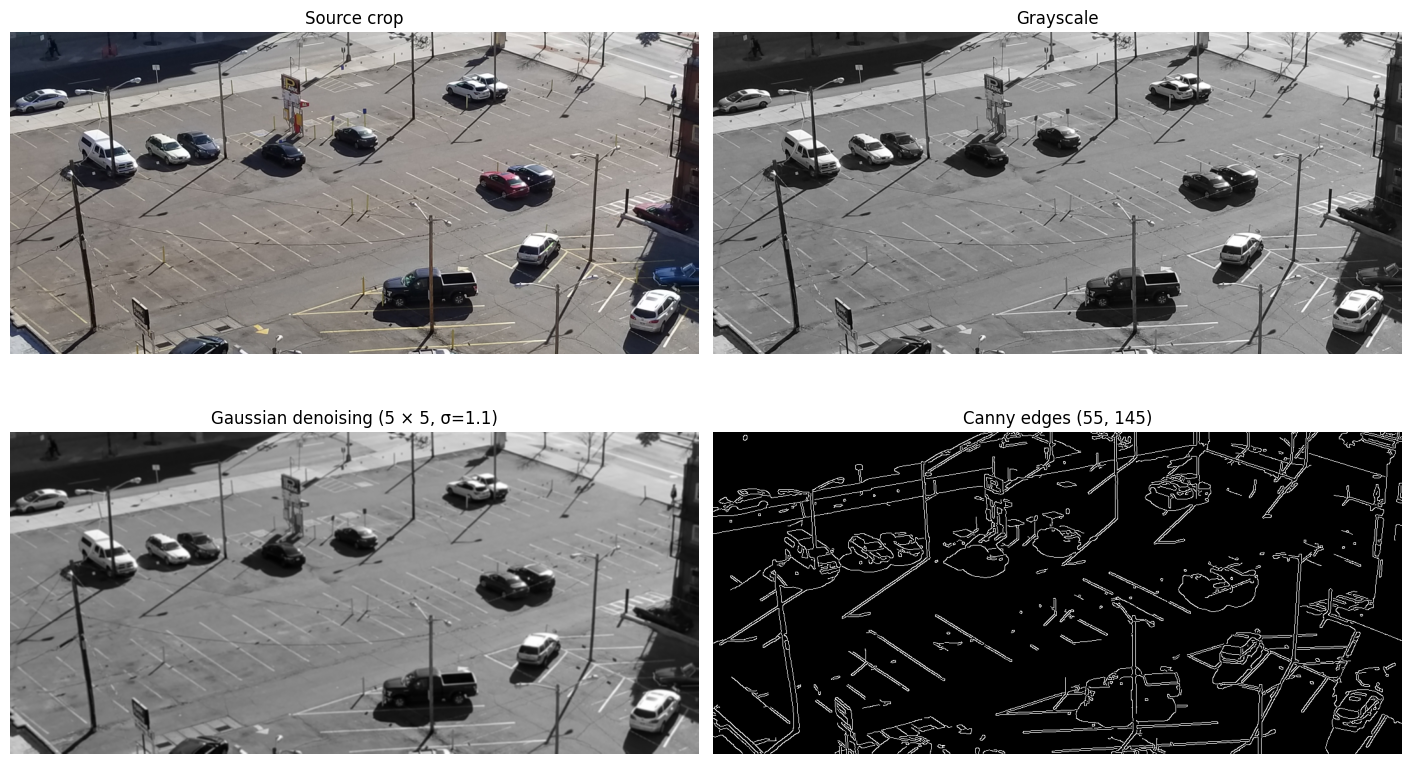

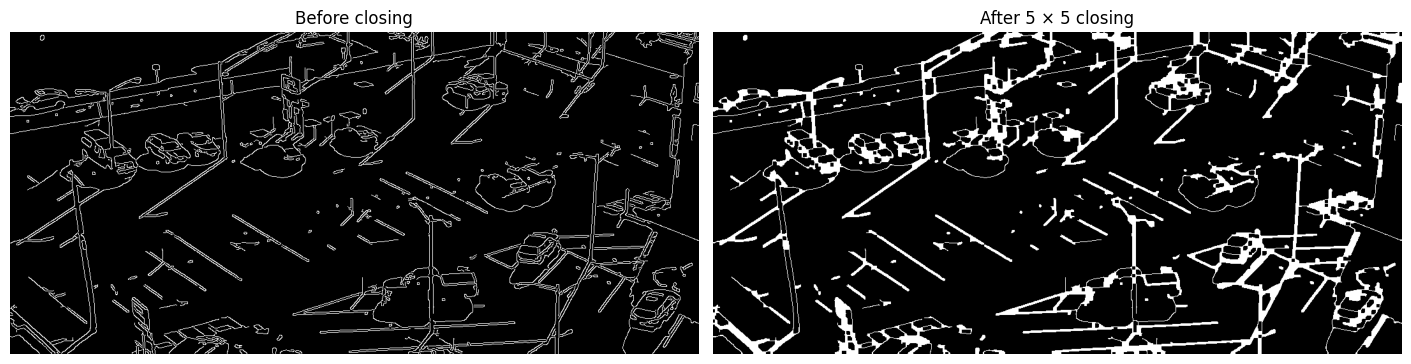

In [3]:
gray = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2GRAY)
denoised = cv2.GaussianBlur(gray, (5, 5), sigmaX=1.1)

CHOSEN = {
    "name": "C — chosen",
    "canny_low": 55,
    "canny_high": 145,
    "closing_kernel": 5,
    "hough_votes": 28,
    "min_line_length": 24,
    "max_line_gap": 12,
}

edges = cv2.Canny(
    denoised, CHOSEN["canny_low"], CHOSEN["canny_high"], L2gradient=True
)
closing_kernel = cv2.getStructuringElement(
    cv2.MORPH_RECT, (CHOSEN["closing_kernel"], CHOSEN["closing_kernel"])
)
closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, closing_kernel, iterations=1)

cv2.imwrite(str(RESULTS_DIR / "grayscale.png"), gray)
cv2.imwrite(str(RESULTS_DIR / "denoised.png"), denoised)
cv2.imwrite(str(RESULTS_DIR / "canny_edges.png"), edges)
cv2.imwrite(str(RESULTS_DIR / "morphological_closing.png"), closed)

fig, axes = plt.subplots(2, 2, figsize=(14, 8), constrained_layout=True)
stages = [
    (crop_rgb, "Source crop", None),
    (gray, "Grayscale", "gray"),
    (denoised, "Gaussian denoising (5 × 5, σ=1.1)", "gray"),
    (edges, "Canny edges (55, 145)", "gray"),
]
for ax, (image, title, cmap) in zip(axes.ravel(), stages):
    ax.imshow(image, cmap=cmap)
    ax.set_title(title)
    ax.axis("off")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
axes[0].imshow(edges, cmap="gray")
axes[0].set_title("Before closing")
axes[1].imshow(closed, cmap="gray")
axes[1].set_title("After 5 × 5 closing")
for ax in axes:
    ax.axis("off")
plt.show()

## Probabilistic Hough segments and rectangle grouping

For every parameter set, `cv2.HoughLinesP` finds line segments on the closed edge image. The grouping procedure:

1. keeps segments in a vehicle-scale length range;
2. pairs segments whose directions differ by at most 9°;
3. requires a plausible separation, overlap, rectangle aspect ratio, and size;
4. scores the implied rotated rectangle using interior edge density, grayscale variation, and contrast with a narrow surrounding ring; and
5. suppresses overlapping or nearly concentric candidates.

The contrast and texture checks remove most pairs formed only by painted parking-space markings. They are generic appearance checks; no vehicle labels or hand-drawn boxes are used.

In [4]:
def preprocess(gray_image, params):
    filtered = cv2.GaussianBlur(gray_image, (5, 5), sigmaX=1.1)
    edge_image = cv2.Canny(
        filtered, params["canny_low"], params["canny_high"], L2gradient=True
    )
    size = params["closing_kernel"]
    kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (size, size))
    morphology = cv2.morphologyEx(edge_image, cv2.MORPH_CLOSE, kernel, iterations=1)
    return filtered, edge_image, morphology


def angle_delta_degrees(a, b):
    return abs((a - b + 90.0) % 180.0 - 90.0)


def rectangle_iou(rect_a, rect_b):
    status, points = cv2.rotatedRectangleIntersection(rect_a, rect_b)
    if status == cv2.INTERSECT_NONE or points is None:
        return 0.0
    intersection = abs(cv2.contourArea(points))
    area_a = rect_a[1][0] * rect_a[1][1]
    area_b = rect_b[1][0] * rect_b[1][1]
    return intersection / (area_a + area_b - intersection + 1e-9)


def rectangle_appearance(rect, gray_image, edge_image):
    box = np.int32(np.round(cv2.boxPoints(rect)))
    mask = np.zeros(gray_image.shape, np.uint8)
    cv2.fillConvexPoly(mask, box, 255)
    pixel_count = cv2.countNonZero(mask)
    if pixel_count == 0:
        return 0.0, 0.0, 0.0

    masked_edges = cv2.bitwise_and(edge_image, edge_image, mask=mask)
    edge_density = cv2.countNonZero(masked_edges) / pixel_count
    inside_mean, inside_std = cv2.meanStdDev(gray_image, mask=mask)

    expanded = (rect[0], (rect[1][0] + 16, rect[1][1] + 16), rect[2])
    ring_mask = np.zeros(gray_image.shape, np.uint8)
    cv2.fillConvexPoly(
        ring_mask, np.int32(np.round(cv2.boxPoints(expanded))), 255
    )
    ring_mask[mask > 0] = 0
    ring_mean = cv2.mean(gray_image, mask=ring_mask)[0]
    local_contrast = abs(float(inside_mean[0, 0]) - ring_mean)
    return float(edge_density), float(inside_std[0, 0]), local_contrast


def hough_rectangles(gray_image, edge_image, morphology, params, max_rectangles=8):
    raw = cv2.HoughLinesP(
        morphology,
        rho=1,
        theta=np.pi / 180,
        threshold=params["hough_votes"],
        minLineLength=params["min_line_length"],
        maxLineGap=params["max_line_gap"],
    )
    raw_values = np.empty((0, 4), dtype=np.int32) if raw is None else raw.reshape(-1, 4)

    segments = []
    for x1, y1, x2, y2 in raw_values:
        vector = np.array([x2 - x1, y2 - y1], dtype=float)
        length = float(np.linalg.norm(vector))
        if not 24 <= length <= 150:
            continue
        unit = vector / length
        if unit[0] < 0:
            unit = -unit
        segments.append(
            {
                "p1": np.array([x1, y1], dtype=float),
                "p2": np.array([x2, y2], dtype=float),
                "unit": unit,
                "angle": np.degrees(np.arctan2(unit[1], unit[0])) % 180,
                "midpoint": np.array([(x1 + x2) / 2, (y1 + y2) / 2]),
                "length": length,
            }
        )

    candidates = []
    for i, first in enumerate(segments):
        for second in segments[i + 1:]:
            if angle_delta_degrees(first["angle"], second["angle"]) > 9:
                continue

            direction = first["unit"]
            normal = np.array([-direction[1], direction[0]])
            midpoint_delta = second["midpoint"] - first["midpoint"]
            width = abs(float(midpoint_delta @ normal))
            along_offset = abs(float(midpoint_delta @ direction))
            if not 18 <= width <= 65:
                continue
            if along_offset > 0.75 * max(first["length"], second["length"]):
                continue

            endpoints = np.vstack(
                [first["p1"], first["p2"], second["p1"], second["p2"]]
            )
            projected = endpoints @ direction
            length = float(projected.max() - projected.min())
            aspect = length / width
            if not (1.55 <= aspect <= 4.2 and 45 <= length <= 145):
                continue

            center = tuple(np.mean(endpoints, axis=0))
            angle = float(np.degrees(np.arctan2(direction[1], direction[0])))
            rect = (center, (length, width), angle)
            density, std, contrast = rectangle_appearance(rect, gray_image, edge_image)
            if density < 0.045 or std < 16 or contrast < 7:
                continue

            area = length * width
            shape_score = max(0.0, 1 - abs(aspect - 2.35) / 2.0)
            area_score = max(0.0, 1 - abs(area - 2600) / 3000)
            score = (
                contrast / 35
                + 1.5 * density
                + min(std / 120, 0.5)
                + 0.25 * shape_score
                + 0.15 * area_score
            )
            candidates.append(
                {"score": score, "rect": rect, "density": density,
                 "std": std, "contrast": contrast}
            )

    height, width = gray_image.shape
    kept = []
    for candidate in sorted(candidates, key=lambda item: item["score"], reverse=True):
        cx, cy = candidate["rect"][0]
        # Border fragments are incomplete by construction and are not useful here.
        if not (40 <= cx <= width - 90 and 24 <= cy <= height - 18):
            continue
        duplicate = False
        for prior in kept:
            center_distance = np.linalg.norm(
                np.asarray(candidate["rect"][0]) - np.asarray(prior["rect"][0])
            )
            if center_distance < 34 or rectangle_iou(candidate["rect"], prior["rect"]) >= 0.15:
                duplicate = True
                break
        if duplicate:
            continue
        kept.append(candidate)
        if len(kept) >= max_rectangles:
            break
    return kept, raw_values


def draw_rectangles(rgb_image, detections, color=(0, 255, 255), thickness=3):
    # OpenCV draws in BGR; convert around the drawing operation for predictable colors.
    canvas = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2BGR)
    for detection in detections:
        box = np.int32(np.round(cv2.boxPoints(detection["rect"])))
        cv2.polylines(canvas, [box], True, color, thickness, cv2.LINE_AA)
        for point in box:
            cv2.circle(canvas, tuple(point), 3, (0, 140, 255), -1, cv2.LINE_AA)
    return cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB)

## Parameter comparison

The grid changes all requested parameter families: Canny thresholds, closing kernel size, Hough vote threshold, minimum segment length, and maximum gap. The number in each title is the number of retained approximate outlines, not a ground-truth accuracy score.

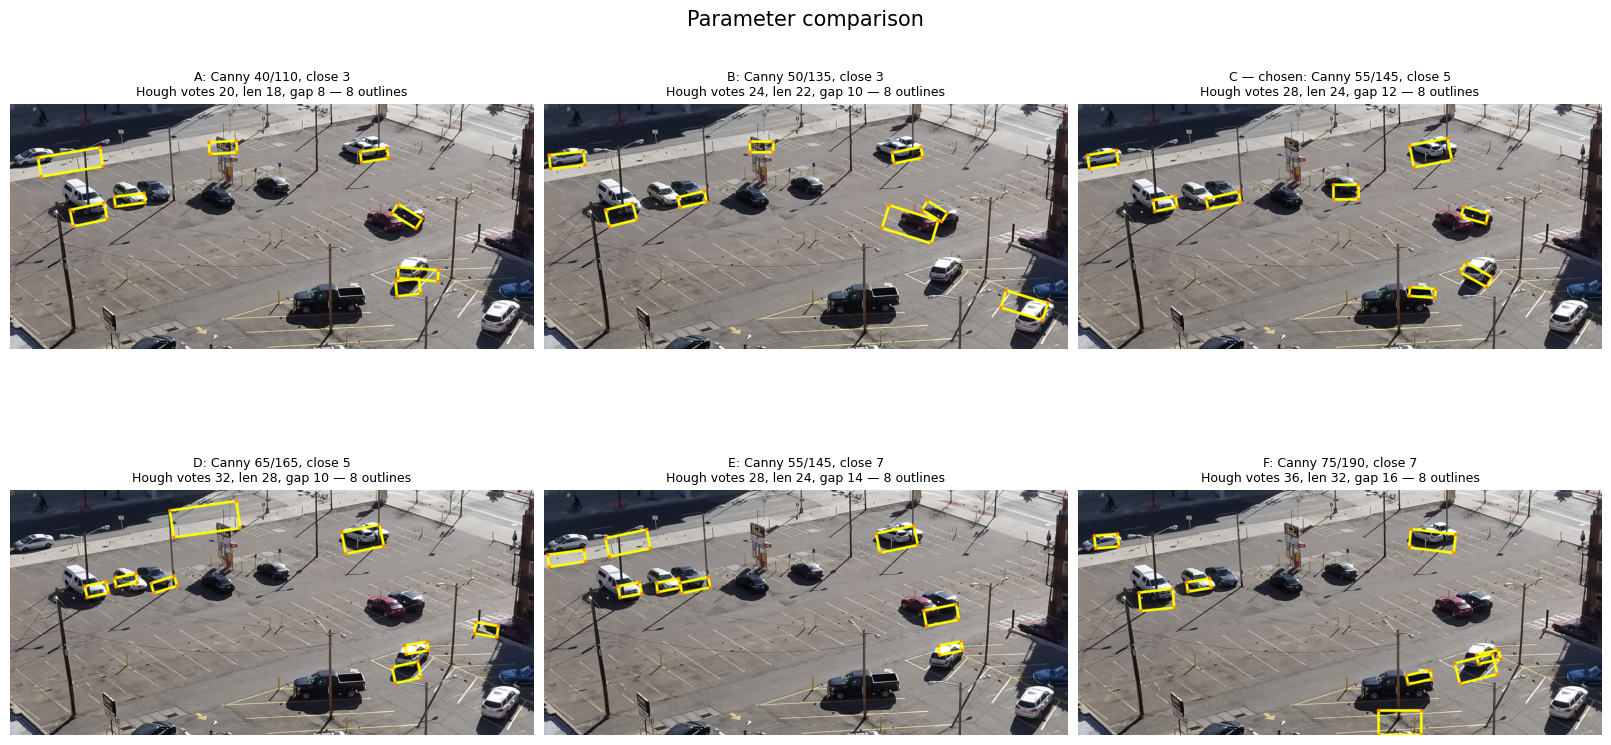

A: 1423 raw Hough segments,  8 retained outlines
B: 1030 raw Hough segments,  8 retained outlines
C — chosen: 1159 raw Hough segments,  8 retained outlines
D:  596 raw Hough segments,  8 retained outlines
E: 1452 raw Hough segments,  8 retained outlines
F:  802 raw Hough segments,  8 retained outlines


In [5]:
PARAMETER_SETS = [
    {"name": "A", "canny_low": 40, "canny_high": 110, "closing_kernel": 3,
     "hough_votes": 20, "min_line_length": 18, "max_line_gap": 8},
    {"name": "B", "canny_low": 50, "canny_high": 135, "closing_kernel": 3,
     "hough_votes": 24, "min_line_length": 22, "max_line_gap": 10},
    CHOSEN,
    {"name": "D", "canny_low": 65, "canny_high": 165, "closing_kernel": 5,
     "hough_votes": 32, "min_line_length": 28, "max_line_gap": 10},
    {"name": "E", "canny_low": 55, "canny_high": 145, "closing_kernel": 7,
     "hough_votes": 28, "min_line_length": 24, "max_line_gap": 14},
    {"name": "F", "canny_low": 75, "canny_high": 190, "closing_kernel": 7,
     "hough_votes": 36, "min_line_length": 32, "max_line_gap": 16},
]

comparison = []
for params in PARAMETER_SETS:
    _, test_edges, test_closed = preprocess(gray, params)
    detections, lines = hough_rectangles(gray, test_edges, test_closed, params)
    comparison.append((params, detections, lines, draw_rectangles(crop_rgb, detections)))

fig, axes = plt.subplots(2, 3, figsize=(16, 8), constrained_layout=True)
for ax, (params, detections, lines, annotated) in zip(axes.ravel(), comparison):
    ax.imshow(annotated)
    ax.set_title(
        f"{params['name']}: Canny {params['canny_low']}/{params['canny_high']}, "
        f"close {params['closing_kernel']}\n"
        f"Hough votes {params['hough_votes']}, len {params['min_line_length']}, "
        f"gap {params['max_line_gap']} — {len(detections)} outlines",
        fontsize=9,
    )
    ax.axis("off")
fig.suptitle("Parameter comparison", fontsize=15)
fig.savefig(RESULTS_DIR / "parameter_comparison.png", dpi=170, bbox_inches="tight")
plt.show()

for params, detections, lines, _ in comparison:
    print(f"{params['name']}: {len(lines):4d} raw Hough segments, {len(detections):2d} retained outlines")

### Visual choice

Setting **C** was selected by visual inspection: Canny `(55, 145)`, a `5 × 5` closing kernel, and Hough settings `votes=28`, `minLineLength=24`, `maxLineGap=12` (all lengths in the resized crop's pixels). A and B retain more short texture segments. E and F connect more parking markings and shadows. D drops some weaker vehicle sides. C gives the best compromise on this crop.

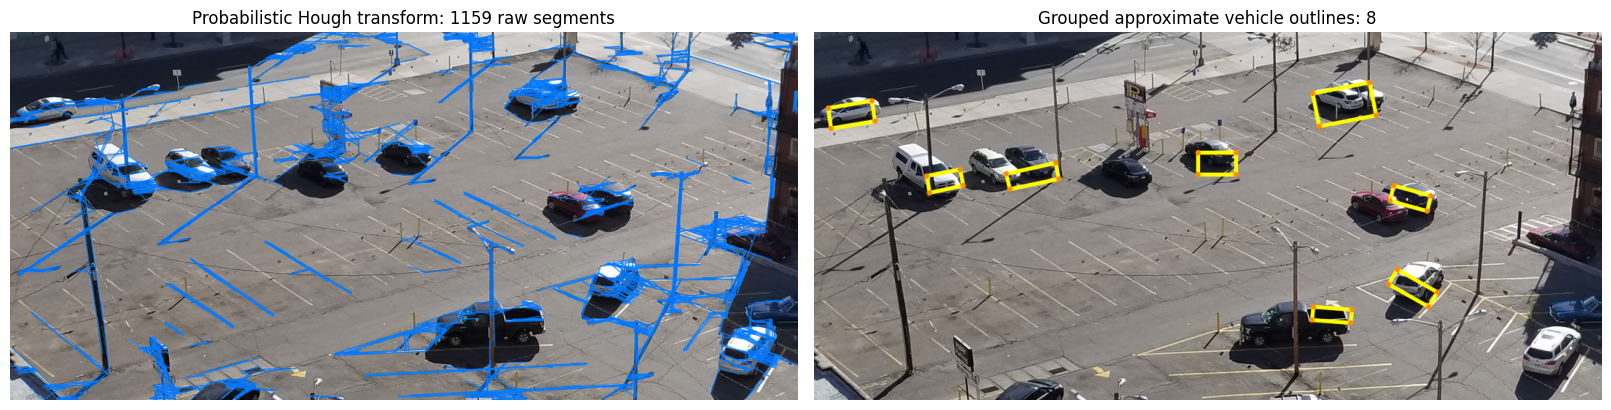

Chosen settings: {'name': 'C — chosen', 'canny_low': 55, 'canny_high': 145, 'closing_kernel': 5, 'hough_votes': 28, 'min_line_length': 24, 'max_line_gap': 12}
Saved /home/sadia/GNR_607/GNR-607-hough-object-extraction/results/final_outline_overlay.png


In [6]:
chosen_detections, chosen_lines = hough_rectangles(gray, edges, closed, CHOSEN)

hough_view = crop_bgr.copy()
for x1, y1, x2, y2 in chosen_lines:
    cv2.line(hough_view, (x1, y1), (x2, y2), (255, 120, 0), 1, cv2.LINE_AA)
cv2.imwrite(str(RESULTS_DIR / "hough_segments.png"), hough_view)

final_rgb = draw_rectangles(crop_rgb, chosen_detections)
final_bgr = cv2.cvtColor(final_rgb, cv2.COLOR_RGB2BGR)
cv2.imwrite(str(RESULTS_DIR / "final_outline_overlay.png"), final_bgr)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), constrained_layout=True)
axes[0].imshow(cv2.cvtColor(hough_view, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Probabilistic Hough transform: {len(chosen_lines)} raw segments")
axes[1].imshow(final_rgb)
axes[1].set_title(f"Grouped approximate vehicle outlines: {len(chosen_detections)}")
for ax in axes:
    ax.axis("off")
plt.show()

print("Chosen settings:", CHOSEN)
print("Saved", RESULTS_DIR / "final_outline_overlay.png")

## Result assessment

The eight cyan outlines follow visible long-side pairs on separated vehicles near the upper left, upper center, and right side. Long parking-space stripes are absent from the final selection because their implied interiors have little texture or contrast relative to surrounding pavement; border rejection also removes the painted-space fragment at the far right that appears in some comparison panels.

Known limitations visible in the final overlay:

- The white van near the upper left and the dark vehicle near the lower center are incomplete: their boxes follow roof/body sides rather than bumper-to-bumper silhouettes.
- The adjacent red and dark vehicles near the upper right are not both recovered; the outline favors the darker vehicle's strongest sides.
- The unoutlined dark vehicle just left of center is a false negative because its body edge blends into its shadow.
- No obvious parking-stripe-only rectangle remains in the final eight, although settings A, D, and F in the comparison grid show how strong shadows or painted fragments can create false outlines.

These failures are expected for a line-only detector. Perspective, rounded bodies, glare, occlusion, painted markings, and long shadows violate the ideal rectangle model.

In [7]:
required_outputs = [
    "source_crop.png",
    "canny_edges.png",
    "morphological_closing.png",
    "parameter_comparison.png",
    "final_outline_overlay.png",
]
for name in required_outputs:
    path = RESULTS_DIR / name
    assert path.exists() and path.stat().st_size > 0, f"Missing output: {path}"
print("All required outputs exist:")
for name in required_outputs:
    print(f"  {RESULTS_DIR / name} ({(RESULTS_DIR / name).stat().st_size:,} bytes)")

All required outputs exist:
  /home/sadia/GNR_607/GNR-607-hough-object-extraction/results/source_crop.png (891,406 bytes)
  /home/sadia/GNR_607/GNR-607-hough-object-extraction/results/canny_edges.png (29,744 bytes)
  /home/sadia/GNR_607/GNR-607-hough-object-extraction/results/morphological_closing.png (25,779 bytes)
  /home/sadia/GNR_607/GNR-607-hough-object-extraction/results/parameter_comparison.png (1,426,531 bytes)
  /home/sadia/GNR_607/GNR-607-hough-object-extraction/results/final_outline_overlay.png (887,559 bytes)
